# 01. Khám phá dữ liệu House Prices

## 1. Đọc dữ liệu và kiểm tra tổng quan

Mục tiêu: đọc dữ liệu gốc, kiểm tra kích thước, sự khác nhau giữa các cột và kiểu dữ liệu. Chưa thay đổi hoặc điền dữ liệu thiếu.


In [1]:
from pathlib import Path
import pandas as pd

# Hỗ trợ chạy từ thư mục notebooks hoặc thư mục gốc dự án.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "raw").is_dir():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Không tìm thấy data/raw. Hãy mở notebook từ thư mục dự án hoặc notebooks."
    )

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Cột chỉ có trong train:", set(train.columns) - set(test.columns))
print("Cột chỉ có trong test:", set(test.columns) - set(train.columns))

display(train.head())
train.info()


Train: (1460, 81)
Test: (1459, 80)
Cột chỉ có trong train: {'SalePrice'}
Cột chỉ có trong test: set()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

### Nhận xét

- Train có 1.460 dòng và 81 cột; test có 1.459 dòng và 80 cột. Hai tập có cùng các cột đầu vào, chỉ train có biến mục tiêu `SalePrice`.
- Train gồm 35 cột int64, 3 cột float64 và 43 cột object. Kiểu dữ liệu lưu trữ chưa phản ánh hoàn toàn ý nghĩa biến; chẳng hạn `MSSubClass` là mã phân loại.


## 2. Kiểm tra giá trị thiếu

Mục tiêu: thống kê số lượng và tỷ lệ NaN trong train/test trước khi quyết định xử lý. NaN có thể xuất phát từ mã biểu thị không có tiện ích hoặc giá trị bị thiếu; cần đối chiếu data_description.txt. Pandas cũng có thể chuyển chuỗi `None` thành NaN, cần lưu ý khi kiểm tra MasVnrType.


In [2]:
# Thống kê NaN theo từng tập, giữ nguyên dữ liệu gốc.
missing_summary = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_missing_pct": train.isna().mean() * 100,
    "test_missing": test.isna().sum(),
    "test_missing_pct": test.isna().mean() * 100,
})

# SalePrice không thuộc schema của test, không phải giá trị thiếu.
missing_summary = missing_summary.drop(index="SalePrice")
missing_summary = missing_summary.loc[
    (missing_summary["train_missing"] > 0)
    | (missing_summary["test_missing"] > 0)
].sort_values("train_missing_pct", ascending=False)

display(missing_summary.round(2))
print("Số cột có NaN trong train:", (train.isna().sum() > 0).sum())
print("Số cột có NaN trong test:", (test.isna().sum() > 0).sum())
print("Số SalePrice bị thiếu:", train["SalePrice"].isna().sum())


,train_missing,train_missing_pct,test_missing,test_missing_pct
PoolQC,1453,99.52,1456.0,99.79
MiscFeature,1406,96.30,1408.0,96.50
Alley,1369,93.77,1352.0,92.67
Fence,1179,80.75,1169.0,80.12
MasVnrType,872,59.73,894.0,61.27
FireplaceQu,690,47.26,730.0,50.03
LotFrontage,259,17.74,227.0,15.56
GarageYrBlt,81,5.55,78.0,5.35
GarageQual,81,5.55,78.0,5.35
GarageFinish,81,5.55,78.0,5.35


Số cột có NaN trong train: 19
Số cột có NaN trong test: 33
Số SalePrice bị thiếu: 0


### Nhận xét

- Train có 19 cột chứa NaN, test có 33 cột; `SalePrice` không thiếu giá trị.
- Các cột có tỷ lệ NaN cao ở cả hai tập gồm `PoolQC` (99,52% / 99,79%), `MiscFeature` (96,30% / 96,50%), `Alley` (93,77% / 92,67%) và `Fence` (80,75% / 80,12%), lần lượt theo train/test.
- Một số cột chỉ xuất hiện NaN trong test, như `MSZoning`, `KitchenQual` và `GarageCars`; tiền xử lý cần hỗ trợ cả những trường hợp này.
- Chưa xóa cột hoặc điền thiếu theo tỷ lệ: cần đối chiếu mô tả để phân biệt không có tiện ích với thiếu thông tin. Riêng `MasVnrType`, cần kiểm tra chuỗi `None` có bị pandas chuyển thành NaN hay không.


## 3. Kiểm chứng ý nghĩa các giá trị NaN


In [3]:
# Đọc lại dưới dạng chuỗi và giữ nguyên các mã NA/None để kiểm chứng.
raw_train = pd.read_csv(DATA_DIR / "train.csv", keep_default_na=False, dtype=str)
raw_test = pd.read_csv(DATA_DIR / "test.csv", keep_default_na=False, dtype=str)

columns_to_check = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "MasVnrType", "LotFrontage", "GarageType", "BsmtQual",
]

rows = []
for name, raw, parsed in [("train", raw_train, train), ("test", raw_test, test)]:
    for column in columns_to_check:
        rows.append({
            "dataset": name,
            "column": column,
            "literal_NA": raw[column].eq("NA").sum(),
            "literal_None": raw[column].eq("None").sum(),
            "empty_string": raw[column].eq("").sum(),
            "parsed_NaN": parsed[column].isna().sum(),
        })

display(pd.DataFrame(rows))

# Hiển thị định nghĩa tương ứng để diễn giải các mã trong file gốc.
import re

description = (DATA_DIR / "data_description.txt").read_text()
sections = re.split(r"\n(?=[A-Za-z0-9]+:)", description)
for section in sections:
    if section.split(":", 1)[0].strip() in columns_to_check:
        print(section.strip())
        print()


,dataset,column,literal_NA,literal_None,empty_string,parsed_NaN
0,train,PoolQC,1453,0,0,1453
1,train,MiscFeature,1406,0,0,1406
2,train,Alley,1369,0,0,1369
3,train,Fence,1179,0,0,1179
4,train,FireplaceQu,690,0,0,690
5,train,MasVnrType,8,864,0,872
6,train,LotFrontage,259,0,0,259
7,train,GarageType,81,0,0,81
8,train,BsmtQual,37,0,0,37
9,test,PoolQC,1456,0,0,1456


LotFrontage: Linear feet of street connected to property

Alley: Type of alley access to property

       Grvl	Gravel
       Pave	Paved
       NA 	No alley access

MasVnrType: Masonry veneer type

       BrkCmn	Brick Common
       BrkFace	Brick Face
       CBlock	Cinder Block
       None	None
       Stone	Stone

BsmtQual: Evaluates the height of the basement

       Ex	Excellent (100+ inches)	
       Gd	Good (90-99 inches)
       TA	Typical (80-89 inches)
       Fa	Fair (70-79 inches)
       Po	Poor (<70 inches
       NA	No Basement

FireplaceQu: Fireplace quality

       Ex	Excellent - Exceptional Masonry Fireplace
       Gd	Good - Masonry Fireplace in main level
       TA	Average - Prefabricated Fireplace in main living area or Masonry Fireplace in basement
       Fa	Fair - Prefabricated Fireplace in basement
       Po	Poor - Ben Franklin Stove
       NA	No Fireplace

GarageType: Garage location
		
       2Types	More than one type of garage
       Attchd	Attached to home
       Basme

### Nhận xét

- Theo bảng kiểm chứng và data_description.txt ở trên, mã `NA` trong các cột tiện ích đã kiểm tra (PoolQC, MiscFeature, Alley, Fence, FireplaceQu, GarageType, BsmtQual) biểu thị không có tiện ích tương ứng; không thể coi toàn bộ là thông tin chưa biết chỉ vì pandas hiển thị NaN.
- `MasVnrType` trong train có 864 chuỗi `None` và 8 chuỗi `NA`, nhưng pandas gộp thành 872 NaN. Test có 878 chuỗi `None` và 16 chuỗi `NA`, gộp thành 894 NaN. Theo mô tả, `None` là không có lớp ốp; cần giữ riêng với thông tin chưa biết mang mã `NA`.
- `LotFrontage` có 259 mã `NA` trong train và 227 trong test; mô tả không định nghĩa NA là không có mặt tiền, nên chưa gán các giá trị này bằng 0.
- Các cột được kiểm tra không có chuỗi rỗng. Kết quả cho thấy cần đọc dữ liệu có kiểm soát các mã thiếu khi xây dựng preprocessing; hiện giữ nguyên train/test để bảo toàn kết quả EDA đã chạy.


## 4. Kiểm tra trùng lặp và mã định danh


In [4]:
# Kiểm tra trùng lặp, tính duy nhất và giao nhau của mã nhà.
features = test.columns.drop("Id").tolist()
quality_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "missing_Id": [train["Id"].isna().sum(), test["Id"].isna().sum()],
    "duplicate_Id": [train["Id"].duplicated().sum(), test["Id"].duplicated().sum()],
    "duplicate_full_row": [train.duplicated().sum(), test.duplicated().sum()],
    "duplicate_features": [
        train.duplicated(subset=features).sum(),
        test.duplicated(subset=features).sum(),
    ],
}, index=["train", "test"])
display(quality_summary)

shared_ids = set(train["Id"]) & set(test["Id"])
print("Số Id xuất hiện trong cả train và test:", len(shared_ids))

# Những nhà có cùng đặc trưng chưa chắc là dòng lỗi; chỉ hiển thị để xem xét.
for name, df in [("train", train), ("test", test)]:
    duplicates = df.duplicated(subset=features, keep=False)
    if duplicates.any():
        print(f"Các dòng trùng toàn bộ đặc trưng trong {name}:")
        display(df.loc[duplicates].sort_values(features, na_position="last"))


,rows,missing_Id,duplicate_Id,duplicate_full_row,duplicate_features
train,1460,0,0,0,0
test,1459,0,0,0,0


Số Id xuất hiện trong cả train và test: 0


### Nhận xét

- Theo bảng `quality_summary`, cả train (1.460 dòng) và test (1.459 dòng) đều không có Id thiếu, Id trùng, dòng trùng toàn bộ hoặc dòng trùng toàn bộ đặc trưng khi bỏ Id và SalePrice.
- Theo phép giao hai tập Id, không có Id xuất hiện đồng thời trong train và test. Chưa phát hiện vấn đề trùng lặp theo các phép kiểm tra này; không cần xóa dòng ở bước này.


## 5. Khám phá phân phối giá nhà SalePrice


Số giá trị thiếu: 0
Số giá trị <= 0: 0


,SalePrice
count,1460.0
mean,180921.2
std,79442.5
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


,SalePrice,log1p(SalePrice)
mean,180921.196,12.024
median,163000.000,12.002
skewness,1.883,0.121


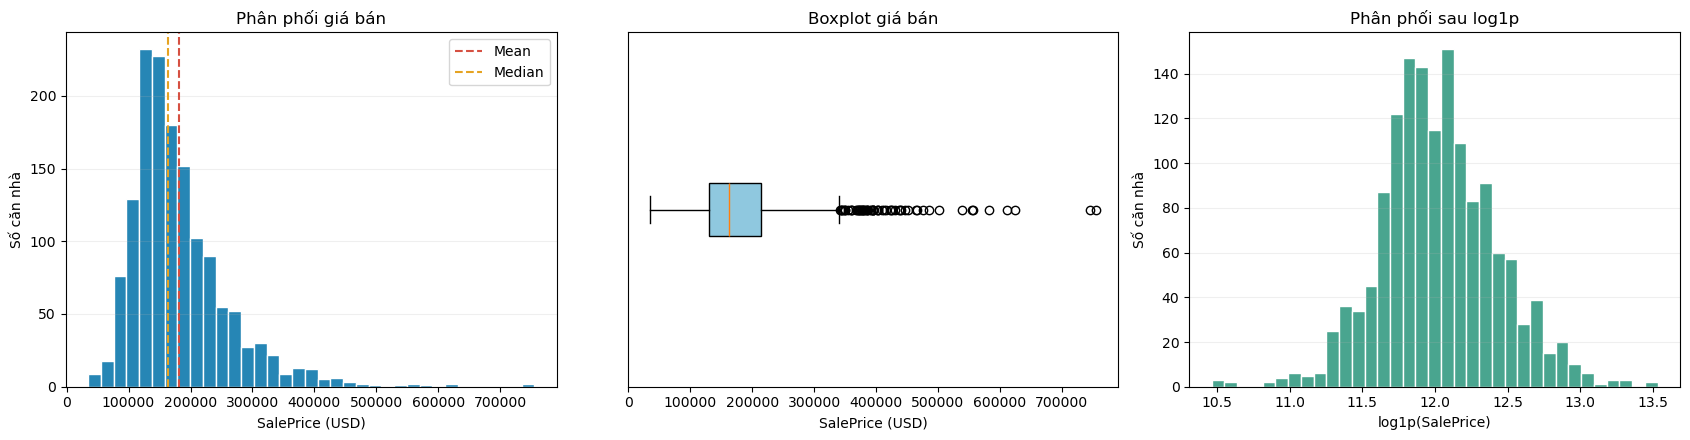

Ngưỡng boxplot theo 1.5 IQR: [3,937.50, 340,037.50]
Số giá nằm ngoài ngưỡng: 61


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Chỉ khám phá trên train; giữ nguyên cột SalePrice gốc.
price = train["SalePrice"]
print("Số giá trị thiếu:", price.isna().sum())
print("Số giá trị <= 0:", price.le(0).sum())
display(price.describe().to_frame("SalePrice").round(2))

if price.dropna().le(0).any():
    raise ValueError("Có giá không dương; cần kiểm tra trước khi xem phân phối log.")

log_price = np.log1p(price)
display(pd.DataFrame({
    "SalePrice": {"mean": price.mean(), "median": price.median(), "skewness": price.skew()},
    "log1p(SalePrice)": {
        "mean": log_price.mean(), "median": log_price.median(), "skewness": log_price.skew()
    },
}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(price.dropna(), bins=35, color="#2686b5", edgecolor="white")
axes[0].axvline(price.mean(), color="#d65042", linestyle="--", label="Mean")
axes[0].axvline(price.median(), color="#e5a322", linestyle="--", label="Median")
axes[0].set(title="Phân phối giá bán", xlabel="SalePrice (USD)", ylabel="Số căn nhà")
axes[0].legend()

axes[1].boxplot(price.dropna(), vert=False, patch_artist=True,
                boxprops={"facecolor": "#8fc8df"})
axes[1].set(title="Boxplot giá bán", xlabel="SalePrice (USD)", yticks=[])

axes[2].hist(log_price.dropna(), bins=35, color="#49a58f", edgecolor="white")
axes[2].set(title="Phân phối sau log1p", xlabel="log1p(SalePrice)", ylabel="Số căn nhà")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

# Các điểm ngoài râu boxplot chỉ được đánh dấu để xem xét, chưa xóa.
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Ngưỡng boxplot theo 1.5 IQR: [{lower:,.2f}, {upper:,.2f}]")
print("Số giá nằm ngoài ngưỡng:", ((price < lower) | (price > upper)).sum())


### Nhận xét

- Theo describe(), SalePrice có đủ 1.460 giá trị, không thiếu và không có giá không dương; giá dao động từ 34.900 đến 755.000 USD.
- Histogram và bảng thống kê cho thấy phân phối lệch phải: trung bình khoảng 180.921 USD lớn hơn trung vị 163.000 USD, skewness là 1,883.
- Sau log1p, skewness giảm còn 0,121 và histogram cân đối hơn. Đây là căn cứ để thử biến đổi mục tiêu khi huấn luyện, chưa khẳng định cải thiện dự đoán nếu chưa đánh giá bằng cross-validation.
- Theo ngưỡng 1,5 IQR [3.937,50; 340.037,50], có 61/1.460 căn nhà (khoảng 4,18%) nằm ngoài râu boxplot. Đây là các giá cực trị cần xem xét, chưa phải lỗi dữ liệu để tự động xóa.


## 6. Mối liên hệ giữa đặc trưng số và giá nhà


In [ ]:
# Pearson chỉ mô tả quan hệ tuyến tính trên các cặp giá trị không thiếu.
# Loại Id và các mã phân loại/thời điểm khỏi biểu đồ tương quan số này.
exclude = ["Id", "MSSubClass", "MoSold", "YrSold", "SalePrice"]
numeric_features = train.select_dtypes(include="number").drop(
    columns=exclude, errors="ignore"
)
correlations = numeric_features.corrwith(train["SalePrice"])
top_correlations = correlations.dropna().loc[
    correlations.dropna().abs().sort_values(ascending=False).head(10).index
].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#2686b5" if value >= 0 else "#d65042" for value in top_correlations]
bars = ax.barh(top_correlations.index, top_correlations.values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set(
    title="10 đặc trưng số có |tương quan Pearson| cao nhất với SalePrice",
    xlabel="Hệ số tương quan Pearson với giá gốc",
    ylabel="Đặc trưng",
)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()
